# Import Dependency

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline
import matplotlib.pyplot as plt
from pathlib import Path
from functools import partial

import itertools

import numpy as np
import autograd.numpy as anp
from autograd import value_and_grad as auto_value_and_grad
import nlopt
import matplotlib.pyplot as plt
from top_opt_framework import problems
from top_opt_framework import topo_api
from top_opt_framework import topo_physics
from scipy.ndimage import zoom
import math

# Beam Settings

In [2]:
# randomly generate an inventory count for each shape, sum of the counts should be N
N = 20

# ---- 2D stock domain: each stock element is a circular arc (curvature kappa, arc length l) ----
# stock points on a kappa x length grid; the Delaunay triangulation of these points
# then covers the whole [kappa_min, kappa_max] x [l_min, l_max] box, so every
# (alpha_k, alpha_l) in [0,1]^2 maps to a point inside the triangulated domain.
# (stock points need not be a grid -- any 2D point set works, as long as its convex hull covers the parameter box)
stock_kappa_vals  = np.array([0.02, 0.04, 0.06, 0.08, 0.1])
stock_length_vals = np.array([0.0, 10.0, 20.0, 30.0, 40.0])
_KK, _LL = np.meshgrid(stock_kappa_vals, stock_length_vals)
beam_stock_prams = np.stack([_KK.ravel(), _LL.ravel()], axis=1)   # (n_stock, 2): [kappa, length]

# inventory count per (kappa, length) stock point.
# the length-0 row plays the role of the old "0" bucket (deleted beams land there).
beam_stock_numbs = np.array([30, 30, 30, 30, 30,     # length 0,  kappa 0 / 0.05 / 0.1 / 0.15 / 0.2
                              4,  4,  4,  4,  4,     # length 10, kappa 0 / 0.05 / 0.1 / 0.15 / 0.2
                              4,  4,  4,  4,  4,     # length 20, kappa 0 / 0.05 / 0.1 / 0.15 / 0.2
                              4,  4,  4,  4,  4,     # length 30, kappa 0 / 0.05 / 0.1 / 0.15 / 0.2
                              4,  4,  4,  4,  4],    # length 40, kappa 0 / 0.05 / 0.1 / 0.15 / 0.2
                            dtype=float)
assert len(beam_stock_numbs) == len(beam_stock_prams)

img_h = 300
img_w = 300
# Output density-field resolution (W x H). Set these to any size you want;
# nelx/nely below must match these so the FEA grid lines up with the density grid.
grid_w = 180   # W (number of columns, x-direction)
grid_h = 120   # H (number of rows, y-direction)
sharpness = 2
target_penalty = 10
boundary_penalty = 10
stock_length_penalty = 10
grad_loss_penalty = 1
n_shapes = N


# Basis Function (Sec. 3.3)

In [3]:
import math
import numpy as np
import autograd.numpy as anp
from scipy.spatial import Delaunay


KAPPA_EPS = 1e-4        # kappa is shifted by this before inverting: R = 1/(kappa + eps).
                        # kappa = 0 then is an arc of radius 1e4 == numerically straight,
                        # and the gradient w.r.t. kappa stays alive at kappa = 0.
                        # (defined here because the sanity-check plot below already needs it)


# ---------- triangulation of the 2D stock domain (kappa, length) ----------
def build_stock_triangulation(stock_points):
    """Delaunay-triangulate the stock points. Returns (simplices, mats, pts):
    simplices (n_tri, 3) vertex indices, mats (n_tri, 2, 2) precomputed inverse
    matrices for barycentric coords, pts (n_stock, 2) the raw stock points.
    Delaunay is run in normalized coordinates (triangle shapes are unaffected by the kappa/length units);
    barycentric coordinates are affine-invariant, so they can be evaluated directly in the original coordinates afterwards."""
    pts = np.asarray(stock_points, dtype=float)          # (n_stock, 2) [kappa, length]
    lo = pts.min(axis=0)
    span = pts.max(axis=0) - lo
    span[span == 0] = 1.0
    tri = Delaunay((pts - lo) / span)
    simplices = tri.simplices.copy()                     # (n_tri, 3)
    mats = []
    for s in simplices:
        v0, v1, v2 = pts[s]
        T = np.array([[v0[0] - v2[0], v1[0] - v2[0]],
                      [v0[1] - v2[1], v1[1] - v2[1]]])
        mats.append(np.linalg.inv(T))
    return simplices, np.stack(mats), pts


def _tri_barycentric(kaps, lens, v2, Minv):
    """Barycentric coords (l0, l1, l2) of points (kaps, lens) w.r.t. one triangle.
    Linear in (kappa, length) -> autograd-differentiable."""
    dx = kaps - v2[0]
    dy = lens - v2[1]
    l0 = Minv[0, 0] * dx + Minv[0, 1] * dy
    l1 = Minv[1, 0] * dx + Minv[1, 1] * dy
    return l0, l1, 1.0 - l0 - l1


# piecewise-linear hat B_i on the triangulation: 1 at stock point i, 0 at all
# other stock points, linear inside each incident triangle (the 2D version of the 1D linear hat)
def hat_func_2d(kaps, lens, vert_idx, simplices, mats, stock_pts, tol=1e-9):
    vals = []
    for t, s in enumerate(simplices):
        s = list(s)
        if vert_idx not in s:
            continue
        lams = _tri_barycentric(kaps, lens, stock_pts[s[2]], mats[t])
        inside = (lams[0] >= -tol) & (lams[1] >= -tol) & (lams[2] >= -tol)
        vals.append(anp.where(inside, lams[s.index(vert_idx)], 0.0))
    if not vals:
        return anp.zeros_like(kaps)
    # max over incident triangles: on shared edges both triangles give the SAME
    # value (PL continuity), so max avoids double counting without changing B_i
    return anp.max(anp.stack(vals), axis=0)


# centroid hat B'_t on triangle t: 0 at the three stock points, 1 at the centroid,
# positive everywhere else in the triangle, continuous across edges.
# In the 1D degenerate case (two barycentric coords), 1.5*(1-max) == 2*min(t,1-t), exactly the original midpoint hat.
def centroid_hat_func(kaps, lens, tri_idx, simplices, mats, stock_pts, tol=1e-9):
    s = simplices[tri_idx]
    l0, l1, l2 = _tri_barycentric(kaps, lens, stock_pts[s[2]], mats[tri_idx])
    inside = (l0 >= -tol) & (l1 >= -tol) & (l2 >= -tol)
    lmax = anp.maximum(anp.maximum(l0, l1), l2)
    return anp.where(inside, 1.5 * (1.0 - lmax), 0.0)


# L_stock: softplus barrier on stock inventory violation, Eq. (7) — 2D version
def soft_stock_func_2d(kaps, lens, stock_pts, stock_numbs, simplices, mats, eta_s=5.0):
    counts = []
    for i in range(len(stock_pts)):
        b = hat_func_2d(kaps, lens, i, simplices, mats, stock_pts)
        counts.append(anp.sum(b))
    total_stock_nums = anp.stack(counts)     # sums to n_beams (partition of unity)
    cost = anp.sum(anp.log1p(anp.exp(eta_s * (total_stock_nums - stock_numbs))))
    return cost


# L_rounding: drives (kappa, length) toward the discrete stock points, Eq. (9) — 2D version
def rounding_func_2d(kaps, lens, simplices, mats, stock_pts):
    vals = [centroid_hat_func(kaps, lens, t, simplices, mats, stock_pts)
            for t in range(len(simplices))]
    b = anp.max(anp.stack(vals), axis=0)     # each point is inside one triangle
    return anp.sum(b ** 2)


# build the triangulation once (constants for the whole notebook)
stock_simplices, stock_mats, stock_pts = build_stock_triangulation(beam_stock_prams)
print(f"stock: {len(stock_pts)} points, {len(stock_simplices)} triangles")


stock: 25 points, 32 triangles


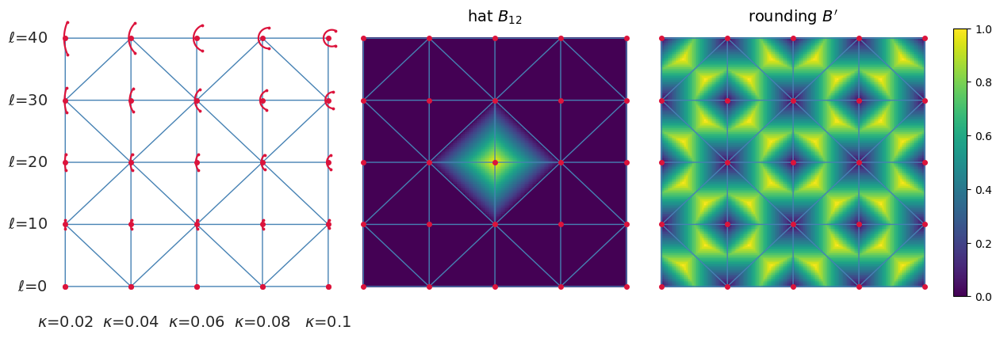

max |sum_i B_i - 1|      = 2.220446049250313e-16
max |sum_i B_i*kappa_i - kappa| = 1.3877787807814457e-17
max |sum_i B_i*l_i - l|  = 7.105427357601002e-15


In [4]:
# ---- sanity check: triangulation, one hat B_i, and the rounding field B' ----
import matplotlib.pyplot as plt
from matplotlib.transforms import ScaledTranslation


def stock_arc_glyph(kappa, length, n_samples=64):
    """Local-frame polyline (n,2) of the arc with this (kappa, length).
    Same convention as _beam_grids_soft: midpoint at the origin, midpoint tangent
    along +y, centre of curvature at (R, 0), R = 1/(kappa + KAPPA_EPS)."""
    k = float(kappa) + KAPPA_EPS
    R = 1.0 / k
    ph = min(float(length) * k / 2.0, math.pi * 0.999)
    psi = np.linspace(-ph, ph, n_samples)
    lx = R * (1.0 - np.cos(psi))
    ly = R * np.sin(psi)
    return np.stack([lx - lx.mean(), ly], axis=1)


def draw_stock_glyphs(ax, stock_pts, glyph_in=0.42, color='crimson', lw=1.6):
    """Draw each stock element's ACTUAL arc shape at its (kappa, length) location.
    Glyphs are laid out in inches (via dpi_scale_trans) rather than data units, so
    they keep a true 1:1 aspect ratio even though the kappa and length axes have
    wildly different scales; one common scale factor keeps sizes comparable."""
    fig = ax.figure
    L_max = max(np.asarray(stock_pts)[:, 1].max(), 1e-12)
    scale = glyph_in / L_max                       # inches per world length unit
    for kk, ll in np.asarray(stock_pts):
        trans = fig.dpi_scale_trans + ScaledTranslation(kk, ll, ax.transData)
        if ll <= 1e-12:                            # zero-length stock -> just a dot
            ax.plot([0], [0], marker='o', ms=4, color=color,
                    transform=trans, clip_on=False, zorder=5)
            continue
        g = stock_arc_glyph(kk, ll) * scale
        ax.plot(g[:, 0], g[:, 1], '-', color=color, lw=lw, transform=trans,
                clip_on=False, zorder=5, solid_capstyle='round')
        ax.plot(g[[0, -1], 0], g[[0, -1], 1], '.', color=color, ms=3.5,
                transform=trans, clip_on=False, zorder=6)


qk, ql = np.meshgrid(np.linspace(stock_pts[:, 0].min(), stock_pts[:, 0].max(), 200),
                     np.linspace(stock_pts[:, 1].min(), stock_pts[:, 1].max(), 200))
qkf, qlf = qk.ravel(), ql.ravel()

i_show = len(stock_pts) // 2   # a middle stock point
B_show = np.asarray(hat_func_2d(qkf, qlf, i_show, stock_simplices, stock_mats, stock_pts)).reshape(qk.shape)
Bp = np.asarray(anp.max(anp.stack([
    centroid_hat_func(qkf, qlf, t, stock_simplices, stock_mats, stock_pts)
    for t in range(len(stock_simplices))]), axis=0)).reshape(qk.shape)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={'wspace': 0.05})
axes[0].triplot(stock_pts[:, 0], stock_pts[:, 1], stock_simplices, color='steelblue', lw=1)
axes[0].plot(stock_pts[:, 0], stock_pts[:, 1], 'o', color='crimson', ms=4)
draw_stock_glyphs(axes[0], stock_pts)          # <- each stock element's real arc shape

# stock points form a grid, so label the edges (3 + 3) instead of every point (9):
# kappa under each column, length to the left of each row -> no crowding
for kk in np.unique(stock_pts[:, 0]):
    axes[0].annotate(f"$\\kappa$={kk:g}", (kk, stock_pts[:, 1].min()), fontsize=14, color='0.15',
                     textcoords='offset points', xytext=(0, -26), ha='center', va='top',
                     annotation_clip=False)
for ll in np.unique(stock_pts[:, 1]):
    axes[0].annotate(f"$\\ell$={ll:g}", (stock_pts[:, 0].min(), ll), fontsize=14, color='0.15',
                     textcoords='offset points', xytext=(-16, 0), ha='right', va='center',
                     annotation_clip=False)
# axes[0].set_title('stock triangulation (red = actual arc shape)')

for ax, Z, ttl in [(axes[1], B_show, f'hat $B_{{{i_show}}}$'), (axes[2], Bp, "rounding $B'$")]:
    im = ax.pcolormesh(qk, ql, Z, shading='auto', vmin=0.0, vmax=1.0)
    ax.triplot(stock_pts[:, 0], stock_pts[:, 1], stock_simplices, color='steelblue', lw=1)
    ax.plot(stock_pts[:, 0], stock_pts[:, 1], 'o', color='crimson', ms=4)
    ax.set_title(ttl, fontsize=14)

# same data limits on all three panels -> the three pictures come out the same size
pad_k = 0.04 * (stock_pts[:, 0].max() - stock_pts[:, 0].min())
pad_l = 0.04 * (stock_pts[:, 1].max() - stock_pts[:, 1].min())
for ax in axes:
    ax.set_xlim(stock_pts[:, 0].min() - pad_k, stock_pts[:, 0].max() + pad_k)
    ax.set_ylim(stock_pts[:, 1].min() - pad_l, stock_pts[:, 1].max() + pad_l)
    ax.set_axis_off()          # no frame / ticks / axis labels, just the picture

# one shared colorbar for both fields (both are plotted on the same 0..1 scale)
fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.025, pad=0.02)
plt.show()

# partition of unity + linear reproduction check
B_all = np.stack([np.asarray(hat_func_2d(qkf, qlf, i, stock_simplices, stock_mats, stock_pts))
                  for i in range(len(stock_pts))])
print("max |sum_i B_i - 1|      =", np.abs(B_all.sum(0) - 1).max())
print("max |sum_i B_i*kappa_i - kappa| =", np.abs(B_all.T @ stock_pts[:, 0] - qkf).max())
print("max |sum_i B_i*l_i - l|  =", np.abs(B_all.T @ stock_pts[:, 1] - qlf).max())

# Beam Merging (Sec. 3.6)

In [5]:
# NOTE ON ARC MERGING
# The straight-beam merge/split postprocess (beam_postprocess.py: merge collinear
# segments, then rebuild params from joints via chord length) does NOT apply to
# arcs: two arcs merge only if they lie on the same circle, and rebuilding an arc
# needs its curvature (see beam_kappa_len returned by params_to_joints), not just
# the two endpoints. Arc-aware merge/split is left as future work. Below we keep
# only the arc joint extraction / IO used for export.

In [6]:
# ---------- arc params -> joint_xy_init + beam_joint_pairs (+ per-arc kappa/length) ----------
def arc_endpoints_np(params_flat):
    """flat (5N,) -> (p0, p1) each (N, 2): the two world-frame endpoints of every arc."""
    n = len(params_flat) // 5
    x, y, theta, al, ak = np.asarray(params_flat).reshape(5, n)
    lens = np.asarray(alphas2lengths(al))
    kaps = np.asarray(alphas2kappas(ak)) + KAPPA_EPS
    R = 1.0 / kaps
    ph = np.minimum(lens * kaps / 2.0, np.pi * 0.999)
    ex = R * (1.0 - np.cos(ph))
    ey = R * np.sin(ph)
    c, s = np.cos(theta), np.sin(theta)
    # local (ex, -ey) and (ex, +ey) -> world
    p0 = np.stack([c*ex - s*(-ey) + x, s*ex + c*(-ey) + y], axis=1)
    p1 = np.stack([c*ex - s*( ey) + x, s*ex + c*( ey) + y], axis=1)
    return p0, p1


def arc_polyline_np(params_flat, i, n_samples=17):
    """(K, 2) world-frame polyline of arc i (for plotting / collision)."""
    n = len(params_flat) // 5
    x, y, theta, al, ak = np.asarray(params_flat).reshape(5, n)
    L = float(np.asarray(alphas2lengths(al[i])))
    k = float(np.asarray(alphas2kappas(ak[i]))) + KAPPA_EPS
    R = 1.0 / k
    ph = min(L * k / 2.0, np.pi * 0.999)
    psi = np.linspace(-ph, ph, n_samples)
    lx = R * (1.0 - np.cos(psi))
    ly = R * np.sin(psi)
    c, s = np.cos(theta[i]), np.sin(theta[i])
    return np.stack([c*lx - s*ly + x[i], s*lx + c*ly + y[i]], axis=1)


def params_to_joints(params_flat, beam_types=None, tol=1e-6):
    """
    params_flat: (5N,) flat params [x | y | theta | alpha_l | alpha_k]
    tol:         endpoint-merge tolerance; endpoints closer than tol are treated as one joint

    Returns:
        joint_xy_init:    (M, 2) float, de-duplicated joint coordinates
        beam_joint_pairs: (N, 2) int,   (start_index, end_index) per arc
        beam_kappa_len:   (N, 2) float, (kappa, length) per arc
                          -- two endpoints alone are not enough to rebuild an arc; its curvature is also needed
    """
    n = len(params_flat) // 5
    p0, p1 = arc_endpoints_np(params_flat)
    endpoints = np.concatenate([p0, p1], axis=0)     # (2N, 2), first N are start points

    # merge endpoints within tolerance -> joint table
    joints = []
    idx_of = np.empty(2 * n, dtype=int)
    for k_, p in enumerate(endpoints):
        for j, q in enumerate(joints):
            if np.hypot(*(p - q)) < tol:
                idx_of[k_] = j
                break
        else:
            idx_of[k_] = len(joints)
            joints.append(p)

    joint_xy_init = np.array(joints, dtype=float)                        # (M, 2)
    beam_joint_pairs = np.stack([idx_of[:n], idx_of[n:]], axis=1)        # (N, 2)

    _, _, _, al, ak = np.asarray(params_flat).reshape(5, n)
    beam_kappa_len = np.stack([np.asarray(alphas2kappas(ak)),
                               np.asarray(alphas2lengths(al))], axis=1)  # (N, 2)
    return joint_xy_init, beam_joint_pairs, beam_kappa_len



In [7]:
# ---------- save / load joints + pairs to txt ----------
def save_truss_txt(path, joint_xy_init, beam_joint_pairs):
    with open(path, "w") as f:
        f.write("# joints (x y)\n")
        f.write(f"{len(joint_xy_init)}\n")
        for x, y in joint_xy_init:
            f.write(f"{x:.6f} {y:.6f}\n")
        f.write("# beams (i0 i1)\n")
        f.write(f"{len(beam_joint_pairs)}\n")
        for i0, i1 in beam_joint_pairs:
            f.write(f"{i0} {i1}\n")


def load_truss_txt(path):
    with open(path) as f:
        lines = [ln.strip() for ln in f if ln.strip() and not ln.startswith("#")]
    m = int(lines[0])
    joint_xy_init = np.array([ln.split() for ln in lines[1:1 + m]], dtype=float)
    n = int(lines[1 + m])
    beam_joint_pairs = np.array([ln.split() for ln in lines[2 + m:2 + m + n]], dtype=int)
    return joint_xy_init, beam_joint_pairs



# Beam Parameters Initialization (Sec. 3.4)

In [8]:
import math
import numpy as np
import autograd.numpy as anp

# ---------- Constants ----------
BEAM_WIDTH = 1
# KAPPA_EPS: defined in the stock-basis cell above (R = 1/(kappa + KAPPA_EPS)).

KAPPA_RANGE  = (float(beam_stock_prams[:, 0].min()), float(beam_stock_prams[:, 0].max()))
LENGTH_RANGE = (float(beam_stock_prams[:, 1].min()), float(beam_stock_prams[:, 1].max()))

# param layout: flat (5N,) array [x | y | theta | alpha_l | alpha_k]
N_PARAMS_PER_BEAM = 5

# kept only for backwards-compatible signatures (beam type is no longer optimized/used)
N_BEAM_TYPES = 1


def alphas2lengths(alphas_l):
    """alpha_l in [0,1] -> arc length in LENGTH_RANGE."""
    return (1 - alphas_l) * LENGTH_RANGE[0] + alphas_l * LENGTH_RANGE[1]

def alphas2kappas(alphas_k):
    """alpha_k in [0,1] -> curvature in KAPPA_RANGE."""
    return (1 - alphas_k) * KAPPA_RANGE[0] + alphas_k * KAPPA_RANGE[1]

def lengths2alphas(lens):
    return (np.asarray(lens) - LENGTH_RANGE[0]) / (LENGTH_RANGE[1] - LENGTH_RANGE[0] + 1e-12)

def kappas2alphas(kaps):
    return (np.asarray(kaps) - KAPPA_RANGE[0]) / (KAPPA_RANGE[1] - KAPPA_RANGE[0] + 1e-12)


# ---------- Sampling ----------
def random_continuous_params(N, x_range, y_range):
    """Returns flat (5N,) array: [x | y | theta | alpha_l | alpha_k]."""
    x       = np.random.uniform(x_range[0], x_range[1], N)
    y       = np.random.uniform(y_range[0], y_range[1], N)
    theta   = np.random.uniform(0, np.pi, N)
    alpha_l = np.random.uniform(0, 1, N)
    alpha_k = np.random.uniform(0, 1, N)
    return np.concatenate([x, y, theta, alpha_l, alpha_k])

def initialize_params(N, x_range, y_range):
    """Returns flat (5N,) array: [x | y | theta | alpha_l | alpha_k]."""
    # uniform
    x = np.linspace(x_range[0] + 5, x_range[1] - 5, N)
    y = np.random.uniform(y_range[0] + 5, y_range[0] + 60, N)
    theta = np.ones(N) * 0
    alpha_l = np.random.uniform(0.9, 1, N)
    alpha_k = np.random.uniform(0.0, 1, N)   # start with mild curvature
    # alpha_k = np.ones(N) * kappas2alphas(0.1)   # start with medium curvature
    print(f"initialize_params: x_range={x_range}, y_range={y_range}, alpha_k={alpha_k}")
    return np.concatenate([x, y, theta, alpha_l, alpha_k])


def random_beam_types(N):
    """Kept for API compatibility; arcs carry (alpha_l, alpha_k) instead of a type."""
    return np.zeros(N, dtype=int)


# ---------- per-arc soft mask: distance field to the arc, differentiable, no resampling ----------
def _beam_grids_soft(params, beam_types, grid_w, grid_h, x_range, y_range, sharpness):
    """
    params: (N,5) anp -> [x, y, theta, alpha_l, alpha_k]
    Returns (N, grid_h, grid_w); each pixel in (0,1): soft membership of that point inside arc i's band (width BEAM_WIDTH).
    Geometry: the arc midpoint is at (x, y), midpoint tangent along the local y axis (world direction (-sin theta, cos theta), matching the original straight-beam long axis),
    center of curvature at local (R, 0), R = 1/(kappa + eps). kappa -> 0 degenerates to a straight beam.
    Fully anp; differentiable w.r.t. x/y/theta/alpha_l/alpha_k. The beam_types argument is kept but no longer used.
    """
    N = params.shape[0]
    cx, cy, th, al, ak = params[:, 0], params[:, 1], params[:, 2], params[:, 3], params[:, 4]

    lens = alphas2lengths(al)                       # (N,) differentiable
    kaps = alphas2kappas(ak) + KAPPA_EPS            # (N,) differentiable, > 0
    R = 1.0 / kaps
    phi_h = anp.minimum(lens * kaps / 2.0, math.pi * 0.999)   # half sweep angle, clamped so the arc never closes into a full circle
    half_w = BEAM_WIDTH / 2.0

    # world coordinates of the target grid (same grid as oc_x, constant)
    xs = np.linspace(x_range[0], x_range[1], grid_w)
    ys = np.linspace(y_range[0], y_range[1], grid_h)
    XX, YY = np.meshgrid(xs, ys)                                # (H,W)

    # grid point -> each arc's local frame (inverse rotation)
    dx = XX[None, :, :] - cx[:, None, None]                     # (N,H,W)
    dy = YY[None, :, :] - cy[:, None, None]
    c = anp.cos(th)[:, None, None]
    s = anp.sin(th)[:, None, None]
    lx =  c * dx + s * dy
    ly = -s * dx + c * dy

    # exact distance field to the arc
    Rb = R[:, None, None]
    ph = phi_h[:, None, None]
    vx = lx - Rb                                   # relative to the center of curvature (R, 0)
    vy = ly
    r = anp.sqrt(vx ** 2 + vy ** 2 + 1e-12)
    psi = anp.arctan2(vy, -vx)                     # angle from the 'center -> arc midpoint' direction
    d_circ = anp.abs(r - Rb)                       # within the sweep: radial distance to the circle
    ex = Rb * (1.0 - anp.cos(ph))                  # the two endpoints (ex, +/-ey)
    ey = Rb * anp.sin(ph)
    d_end1 = anp.sqrt((lx - ex) ** 2 + (ly - ey) ** 2 + 1e-12)
    d_end2 = anp.sqrt((lx - ex) ** 2 + (ly + ey) ** 2 + 1e-12)
    d = anp.where(anp.abs(psi) <= ph, d_circ, anp.minimum(d_end1, d_end2))

    # soft band: sigmoid (differentiable substitute for a boolean test)
    soft = 1.0 / (1.0 + anp.exp(-sharpness * (half_w - d)))

    # gate: as length -> 0, the whole arc's contribution -> 0 (same as the straight-beam version)
    gate = 1.0 - anp.exp(-2.0 * sharpness * (lens[:, None, None] / 2.0))
    return soft * gate                              # (N,H,W) ∈(0,1)


# ---------- differentiable on-arc sample points (shared by boundary loss / visualization) ----------
def arc_sample_points_world(params_batch, n_samples=9):
    """flat (5N,) params -> (wx, wy), each (N, n_samples): points along each arc in world frame."""
    N = params_batch.shape[0] // N_PARAMS_PER_BEAM
    p = params_batch.reshape(N_PARAMS_PER_BEAM, N).T
    cx, cy, th, al, ak = p[:, 0], p[:, 1], p[:, 2], p[:, 3], p[:, 4]
    lens = alphas2lengths(al)
    kaps = alphas2kappas(ak) + KAPPA_EPS
    R = 1.0 / kaps
    ph = anp.minimum(lens * kaps / 2.0, math.pi * 0.999)
    u = np.linspace(-1.0, 1.0, n_samples)[None, :]              # (1,K) constant
    psi = ph[:, None] * u                                        # (N,K)
    lx = R[:, None] * (1.0 - anp.cos(psi))
    ly = R[:, None] * anp.sin(psi)
    c = anp.cos(th)[:, None]
    s = anp.sin(th)[:, None]
    wx = c * lx - s * ly + cx[:, None]
    wy = s * lx + c * ly + cy[:, None]
    return wx, wy


# ---------- Density map ----------
def params_to_density_map(params_batch, beam_types, grid_w, grid_h,
                          x_range, y_range, sdf_x_range=None, sdf_y_range=None,
                          sharpness=2.0):
    """
    params_batch: flat (5N,) anp array (optimization variables)
    beam_types:   (N,) np array (kept for API compatibility, no longer used)
    Returns (grid_h, grid_w), density in [0.001, 1], differentiable.
    """
    N = params_batch.shape[0] // N_PARAMS_PER_BEAM
    params = params_batch.reshape(N_PARAMS_PER_BEAM, N).T       # (N,5), keeps gradient

    soft = _beam_grids_soft(params, beam_types, grid_w, grid_h,
                            x_range, y_range, sharpness)
    union = 1.0 - anp.prod(1.0 - soft, axis=0)                  # soft union in (0,1)
    density = union * (1.0 - 0.001) + 0.001                     # map to [0.001, 1]
    return density


# ---------- Overlap map ----------
def params_to_overlap_map(params_batch, beam_types, grid_w, grid_h,
                          x_range, y_range, sdf_x_range=None, sdf_y_range=None,
                          sharpness=2.0):
    """Returns (grid_h, grid_w): per-pixel sum of the arc soft masks, measures overlap. Differentiable."""
    N = params_batch.shape[0] // N_PARAMS_PER_BEAM
    params = params_batch.reshape(N_PARAMS_PER_BEAM, N).T
    soft = _beam_grids_soft(params, beam_types, grid_w, grid_h,
                            x_range, y_range, sharpness)
    return anp.sum(soft, axis=0)


In [9]:
# ---------- Driver ----------
sdf_x_range = (-25, 25)
sdf_y_range = (-25, 25)
x_range = (-60, 60)
y_range = (-40, 40)

params_batch = initialize_params(n_shapes, x_range, y_range)
beam_types   = random_beam_types(n_shapes)

density_map = params_to_density_map(
    params_batch, beam_types,
    grid_w=grid_w, grid_h=grid_h,
    x_range=x_range, y_range=y_range,
    sdf_x_range=sdf_x_range, sdf_y_range=sdf_y_range, sharpness=sharpness
)
overlap_map = params_to_overlap_map(
    params_batch, beam_types,
    grid_w=grid_w, grid_h=grid_h,
    x_range=x_range, y_range=y_range,
    sdf_x_range=sdf_x_range, sdf_y_range=sdf_y_range, sharpness=sharpness
)

initialize_params: x_range=(-60, 60), y_range=(-40, 40), alpha_k=[0.78065617 0.07778498 0.8015607  0.96794189 0.66418297 0.10595331
 0.68675744 0.80279356 0.76827051 0.78071506 0.58432081 0.31777757
 0.39386732 0.99914718 0.87598394 0.21859823 0.71766425 0.43421413
 0.95452735 0.32077941]


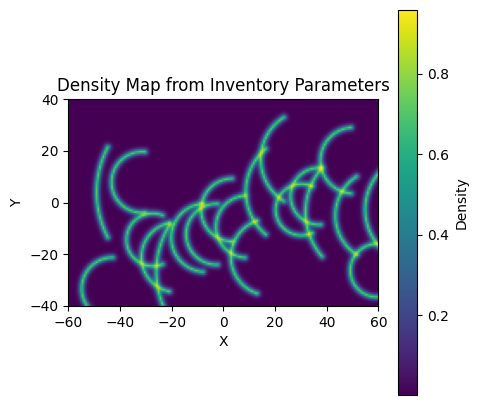

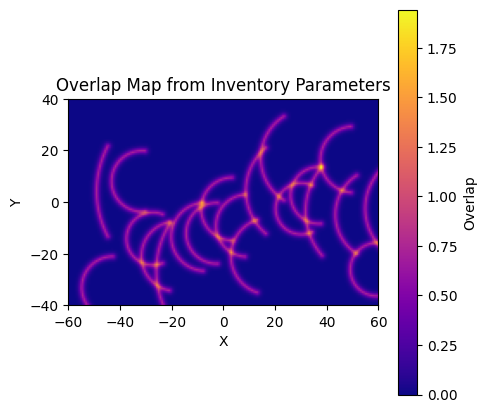

In [10]:
# visualize the density map
plt.figure(figsize=(5, 5))
plt.imshow(density_map, extent=(x_range[0], x_range[1], y_range[0], y_range[1]), origin='lower', cmap='viridis')
plt.title('Density Map from Inventory Parameters')
plt.xlabel('X')
plt.ylabel('Y')
plt.colorbar(label='Density')
plt.show()

# visualize the overlap map
plt.figure(figsize=(5, 5))
plt.imshow(overlap_map, extent=(x_range[0], x_range[1], y_range[0], y_range[1]), origin='lower', cmap='plasma')
plt.title('Overlap Map from Inventory Parameters')
plt.xlabel('X')
plt.ylabel('Y')
plt.colorbar(label='Overlap')
plt.show()

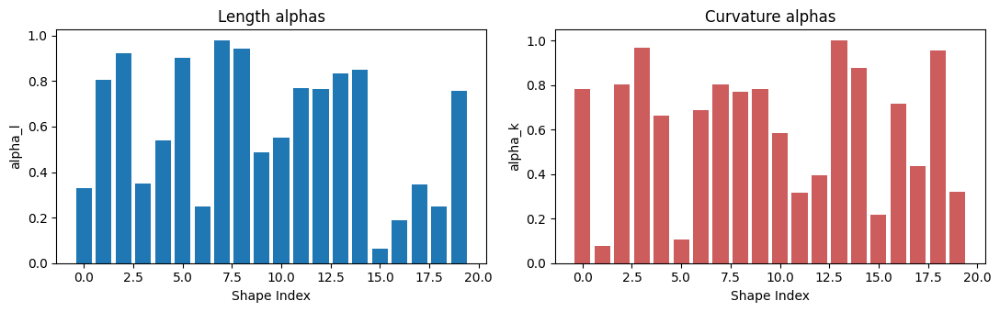

In [11]:
# show alphas
# assign all alpha_l in params_batch to random, others remain unchanged
params_batch[3*n_shapes:4*n_shapes] = np.random.uniform(0, 1, n_shapes)
alphas_l = params_batch.reshape(5, n_shapes)[3]
alphas_k = params_batch.reshape(5, n_shapes)[4]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
ax1.bar(range(n_shapes), alphas_l)
ax1.set(xlabel="Shape Index", ylabel="alpha_l", title="Length alphas")
ax2.bar(range(n_shapes), alphas_k, color='indianred')
ax2.set(xlabel="Shape Index", ylabel="alpha_k", title="Curvature alphas")
plt.tight_layout(); plt.show()


# Boundary Condition Settings

121 fixed nodes


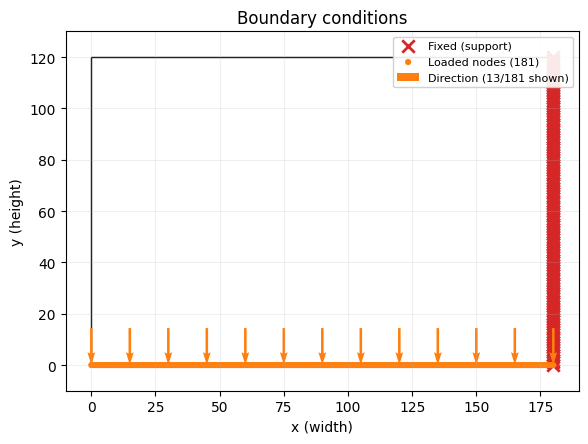

In [12]:
import numpy as np
import matplotlib.pyplot as plt

def plot_boundary_conditions(problem, ax=None, density=None,
                             pad=None, load_stride=None, fix_stride=1):
    """Visualize a Problem's supports (normals) and loads (forces).

    pad:         extra space around the domain so out-of-frame arrows stay visible.
                 Default: 10% of max(W,H).
    load_stride: subsample for the load DIRECTION arrows only (every k-th node).
                 Default: auto-pick so ~12 arrows are shown.
                 All loaded nodes are still marked with an orange dot regardless.
    fix_stride:  subsample fixed-node crosses (default 1 = show all).
    """
    normals = np.asarray(problem.normals)
    forces  = np.asarray(problem.forces)
    Wp1, Hp1, _ = normals.shape
    W, H = Wp1 - 1, Hp1 - 1

    if pad is None:
        pad = 0.10 * max(W, H)

    if ax is None:
        _, ax = plt.subplots(figsize=(7, 7 * H / max(W, 1)))

    if density is not None:
        ax.imshow(np.asarray(density).T, origin='lower', cmap='gray_r',
                  extent=(0, W, 0, H), vmin=0, vmax=1, alpha=0.6)
    else:
        ax.add_patch(plt.Rectangle((0, 0), W, H, fill=False, ec='black', lw=1))

    ii, jj = np.meshgrid(np.arange(Wp1), np.arange(Hp1), indexing='ij')

    # --- Fixed nodes: red cross ---------------------------------------
    fixed_any = (normals[..., 0] > 0) | (normals[..., 1] > 0)
    fix_i, fix_j = ii[fixed_any], jj[fixed_any]
    if fix_stride > 1 and len(fix_i):
        fix_i = fix_i[::fix_stride]; fix_j = fix_j[::fix_stride]
    print(len(fix_i), "fixed nodes")
    ax.scatter(fix_i, fix_j, marker='x', s=80, c='tab:red', linewidths=2,
               label='Fixed (support)')

    # --- Loads --------------------------------------------------------
    fxv = forces[..., 0]; fyv = forces[..., 1]
    has_load = (fxv != 0) | (fyv != 0)
    li_all, lj_all = ii[has_load], jj[has_load]

    # (a) Mark EVERY loaded node with an orange dot
    if len(li_all):
        ax.scatter(li_all, lj_all, marker='o', s=20,
                   c='tab:orange', edgecolors='none',
                   label=f'Loaded nodes ({len(li_all)})')

    # (b) Sparse direction arrows on top
    lux_all = fxv[has_load]; luy_all = fyv[has_load]
    n_loads = len(li_all)
    if n_loads:
        if load_stride is None:
            load_stride = max(1, n_loads // 12)     # ~12 arrows by default
        sel = slice(None, None, load_stride)
        li, lj = li_all[sel], lj_all[sel]
        lux, luy = lux_all[sel], luy_all[sel]
        mag = np.sqrt(lux**2 + luy**2) + 1e-12
        ux, uy = lux / mag, luy / mag
        arrow_len = 0.08 * max(W, H)
        # Place arrow so the tip sits ON the node.
        x0 = li - ux * arrow_len
        y0 = lj - uy * arrow_len
        ax.quiver(x0, y0, ux * arrow_len, uy * arrow_len,
                  angles='xy', scale_units='xy', scale=1.0,
                  color='tab:orange', width=0.005,
                  label=f'Direction ({len(li)}/{n_loads} shown)')

    ax.set_xlim(-pad, W + pad)
    ax.set_ylim(-pad, H + pad)
    ax.set_aspect('equal')
    ax.set_xlabel('x (width)'); ax.set_ylabel('y (height)')
    ax.set_title('Boundary conditions')
    ax.legend(loc='upper right', fontsize=8, framealpha=0.9)
    ax.grid(alpha=0.2)
    return ax


# center_support
# example 2
# example
# cube
# staircase
problem = problems.center_support(height=grid_h, width=grid_w)
args = topo_api.specified_task(problem)
args["youngs_modulus"] = 1.0
args["volfrac"]=0.1
args["filter_width"]=1
args["g"]=0
env = topo_api.Environment(args)

nely = grid_h
nelx = grid_w

density_func = lambda x : params_to_density_map(
    x, beam_types=beam_types,
    grid_w=grid_w, grid_h=grid_h,
    x_range=x_range, y_range=y_range,
    sdf_x_range=sdf_x_range, sdf_y_range=sdf_y_range, sharpness=sharpness
)
overlap_func = lambda x: params_to_overlap_map(
    x, beam_types=beam_types,
    grid_w=grid_w, grid_h=grid_h,
    x_range=x_range, y_range=y_range,
    sdf_x_range=sdf_x_range, sdf_y_range=sdf_y_range, sharpness=sharpness
)
compliance_fn = lambda x: env.objective(density_func(x), volume_constraint=False)

# Usage:plot_boundary_conditions(problem, pad=5, load_stride=8)   # very sparse
plot_boundary_conditions(problem, pad=10)                  # auto stride
plt.show()

# Density Method (SIMP)

In [13]:
oc_iterations = 50
# (grid_h x grid_w) ones-like array  (rows=H, cols=W)
oc_x = np.ones((grid_h, grid_w)) * 0.13
for it in range(oc_iterations):
    c, x_next = topo_physics.optimality_criteria_step(oc_x, env.ke, env.args)
    # x_next[62:120, :] = 0.001
    # x_next[50:, 50:] = 0.001
    if np.isnan(c):
        print(f"NaN encountered at iteration {it}, stopping.")
        break
    oc_x = x_next

# oc_x = (oc_x >= 0.4).astype(float)

In [14]:
# oc_x[:,:] = 0.01
# # oc_x[62:120, :] = 1.01
# oc_x[50:, 50:] = 1.01
# # oc_x[:,125:] = 1.01

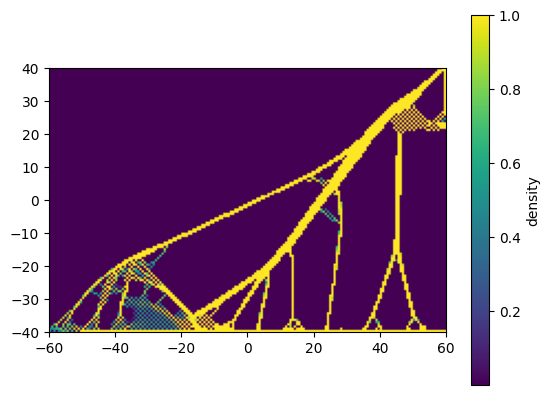

In [15]:
from scipy.ndimage import uniform_filter
from skimage.restoration import inpaint_biharmonic 
oc_x = uniform_filter(oc_x, size=1)

# mask_unknown = oc_x <= 0.4
# u = inpaint_biharmonic(oc_x, mask_unknown)
# oc_x[oc_x < 0.2] = 0
plt.imshow(oc_x, extent=(*x_range, *y_range), origin='lower')
plt.colorbar(label='density')
plt.show()

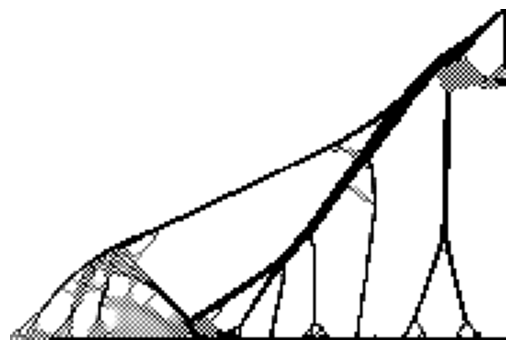

In [16]:
plt.imshow(oc_x, extent=(*x_range, *y_range), origin='lower',
           cmap='gray_r', vmin=0, vmax=1)
# plt.colorbar(label='density')
plt.axis('off')
plt.gcf().patch.set_facecolor('white')
plt.show()

In [17]:
env.objective(oc_x)

98.96911229873257

In [18]:
np.mean(oc_x)

0.0999999999999983

# Visualize the Gradient Flow

compliance = 2971515754.965889
sens shape  = (120, 180)  min/max = -1664791790747.8955 14888.063976929752


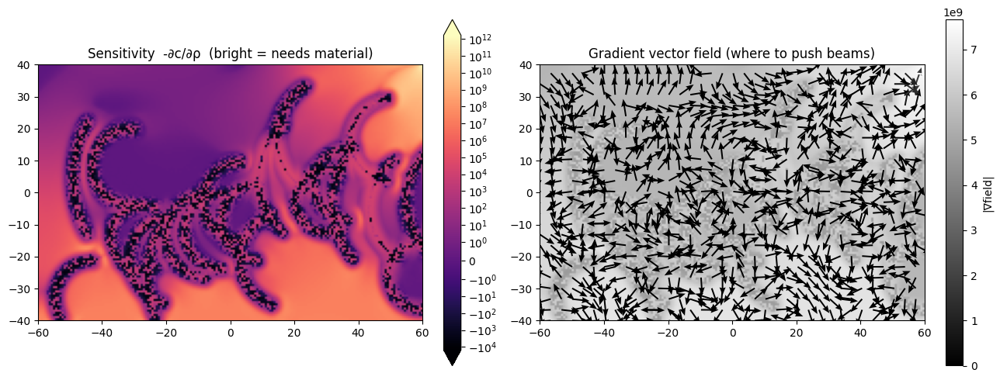

In [19]:
import autograd.numpy as anp
from autograd import value_and_grad as auto_value_and_grad
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from matplotlib.colors import SymLogNorm

# 1) density field -- here the solid field with beams laid out
density0 = density_map

def sensitivity_loss(density):                       
    compliance_grad = auto_value_and_grad(env.objective)(density)[1]
    sensitivity_norm = (compliance_grad - compliance_grad.min()) / (compliance_grad.max() - compliance_grad.min() + 1e-8)
    dark_weight = 1.0 - sensitivity_norm             
    return anp.sum(density * dark_weight)

def overlap_loss(x):
    return anp.sum(anp.log1p(anp.exp(5 * (x - 1))))

# 2) gradient of compliance w.r.t. each pixel density (sensitivity field)
compliance, sens = auto_value_and_grad(
    lambda d:
      env.objective(d, volume_constraint=False) 
#     + overlap_loss(d)
# +
#  sensitivity_loss(d) * grad_loss_penalty
)(density0)

print("compliance =", float(compliance))
print("sens shape  =", sens.shape, " min/max =", sens.min(), sens.max())

# 3) sensitivity field
field = -sens                      # larger = more material should be added here

# no material should be added inside a beam: push existing-material cells to the min (do this in numpy, not anp)
field = np.asarray(field, dtype=float)
# field[density0 > 0.5] = field.min()     # use > 0.5 as the solid test; set to field.min() to fully mask it out

# smooth (optional)
# field = gaussian_filter(field, sigma=2)

gy, gx = np.gradient(field)        # gy: along rows (y), gx: along cols (x)

# downsample so the arrows do not clump together
step = max(1, min(grid_h, grid_w) // 22)
ys, xs = np.mgrid[0:grid_h:step, 0:grid_w:step]
U = gx[::step, ::step]
V = gy[::step, ::step]

# normalize to unit vectors: equal-length arrows, magnitude shown by color
mag = np.hypot(U, V)
Un = U / (mag + 1e-8)
Vn = V / (mag + 1e-8)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# left: sensitivity scalar field -- SymLogNorm handles cross-magnitude + negative values
im = ax[0].imshow(
    field, origin='lower', extent=(*x_range, *y_range), cmap='magma',
    norm=SymLogNorm(linthresh=1, vmin=field.min(), vmax=field.max())
)
ax[0].set_title("Sensitivity  -∂c/∂ρ  (bright = needs material)")
plt.colorbar(im, ax=ax[0], fraction=0.046, extend='both')

# right: vector field
ax[1].imshow(field, origin='lower', extent=(*x_range, *y_range),
             cmap='gray', alpha=0.4,
             norm=SymLogNorm(linthresh=1, vmin=field.min(), vmax=field.max()))
xw = anp.interp(xs, [0, grid_w - 1], x_range)
yw = anp.interp(ys, [0, grid_h - 1], y_range)

q = ax[1].quiver(xw, yw, Un, Vn, mag,
                 cmap='gray', angles='xy',
                 scale_units='width', scale=22,    # smaller = longer arrows (try 15/10/8)
                 width=0.004,                       # shaft width; 0.001 is too thin to see
                 headwidth=4, headlength=5, headaxislength=4.5)
plt.colorbar(q, ax=ax[1], fraction=0.046, label='|∇field|')
ax[1].set_title("Gradient vector field (where to push beams)")
ax[1].set_xlim(x_range); ax[1].set_ylim(y_range)
plt.tight_layout(); plt.show()

In [20]:
print("nan:", np.isnan(field).sum(), " inf:", np.isinf(field).sum())
print("range:", np.nanmin(field), np.nanmax(field))

nan: 0  inf: 0
range: -14888.063976929752 1664791790747.8955


# Objective Function Settings (Sec. 3.3)

In [21]:
weight_compliance = 5
weight_overlap = 100
weight_length = 1000
weight_kappa = 1000
weight_stock = 1000
weight_rounding = 100

In [22]:
# add a constraint function, make x similar to oc_x

def boundary_loss(params_batch, x_range, y_range, n_samples=9):
    """Penalize the amount of each arc that lies outside the box (squared hinge),
    evaluated on n_samples points along each arc (endpoints included)."""
    wx, wy = arc_sample_points_world(params_batch, n_samples=n_samples)   # (N,K)
    x_min, x_max = x_range
    y_min, y_max = y_range
    over = (anp.maximum(0.0, x_min - wx) ** 2
          + anp.maximum(0.0, wx - x_max) ** 2
          + anp.maximum(0.0, y_min - wy) ** 2
          + anp.maximum(0.0, wy - y_max) ** 2)
    return anp.sum(over)

def overlap_loss(x):
    return anp.sum(anp.log1p(anp.exp(5 * (x - 0.75))))
    # return anp.sum(anp.exp(5 * (x - 0.75)))

boundary_fn = lambda x: boundary_loss(x, x_range, y_range)
overlap_fn = lambda x: (overlap_loss(overlap_func(x)))
constraint_fn = lambda x: (density_func(x)*oc_x).sum()

def gradloss_fn(x):
    density_field = density_func(x)
    compliance_grad = auto_value_and_grad(env.objective)(density_field)[1]
    _LOG10 = anp.log(10.0)
    compliance_grad_log = anp.sign(compliance_grad) * anp.log(anp.abs(compliance_grad) + 1e-5) / _LOG10
    min_grad_log = anp.min(compliance_grad_log)
    compliance_grad_log = compliance_grad_log - min_grad_log
    return anp.sum(compliance_grad_log*density_field)

match_target_fn = lambda x: anp.sum(anp.abs(density_func(x) - oc_x))

def compliance_sens_loss(x):
    density_field = density_func(x)
    compliance_grad = auto_value_and_grad(env.objective)(density_field)[1]
    compliance_grad = anp.log10(- compliance_grad + 1e-5)
    return anp.sum(compliance_grad * density_field)

def sensitivity_weighted_coverage_loss(x):
    density = density_func(x)
    compliance_grad = auto_value_and_grad(env.objective)(density)[1]
    sensitivity_norm = (compliance_grad - compliance_grad.min()) / (compliance_grad.max() - compliance_grad.min() + 1e-8)
    dark_weight = 1.0 - sensitivity_norm
    return anp.sum(density * dark_weight)

def alpha_sum_loss(x):
    alphas_l = x.reshape(5, n_shapes)[3]
    return anp.sum(alphas_l)

def kappa_sum_loss(x):
    alphas_k = x.reshape(5, n_shapes)[4]
    return anp.sum(alphas_k)

def volume_loss(x):
    density = density_func(x)
    return (((anp.mean(density) - 0.066)*100)**2)**5

def avoid_region_loss(x, avoid_mask):
    density_field = density_func(x)
    overlap_with_mask = density_field * avoid_mask
    return anp.sum(overlap_with_mask)

avoid_fn = lambda x: avoid_region_loss(x, avoid_mask=oc_x)


# ---- stock / rounding on the 2D (kappa, length) domain ----
def _lens_kaps(x):
    p = x.reshape(5, n_shapes)
    return alphas2lengths(p[3]), alphas2kappas(p[4])

def stock_loss_fn(x):
    lens, kaps = _lens_kaps(x)
    return soft_stock_func_2d(kaps, lens, stock_pts, beam_stock_numbs,
                              stock_simplices, stock_mats)

def rounding_loss_fn(x):
    lens, kaps = _lens_kaps(x)
    return rounding_func_2d(kaps, lens, stock_simplices, stock_mats, stock_pts)


objective_fn = lambda x: (
    compliance_fn(x)*weight_compliance
    + overlap_fn(x)*weight_overlap
    + alpha_sum_loss(x)*weight_length
    + kappa_sum_loss(x)*weight_kappa
    + stock_loss_fn(x)*weight_stock
    + rounding_loss_fn(x)*weight_rounding
)


In [23]:
loss, g = auto_value_and_grad(objective_fn)(params_batch)

## Optimization Scheme (Sec. 3.5)

In [24]:
def topology_optmization(x, optimizer, iterations, ls_max_backtracks, ls_shrink, ls_tol, alpha_round_thresh):
    # N is counted from x (= n_shapes); layout [x | y | theta | alpha_l | alpha_k], each block length N.
    N = x.shape[0] // 5

    lower = torch.tensor([-60.]*N + [-40.]*N + [-float(np.inf)]*N + [0.]*N + [0.]*N, dtype=torch.float64)
    upper = torch.tensor([ 60.]*N + [ 40.]*N + [ float(np.inf)]*N + [1.]*N + [1.]*N, dtype=torch.float64)

    # alpha_l block (length): rounding it to 0 kills the beam.
    alpha_l_start = 3 * N
    alpha_l_end   = 4 * N
    alpha_frozen  = np.zeros(N, dtype=bool)

    losses, frames = [], []
    x0_np = x.detach().cpu().numpy().copy()
    frames.append(x0_np)
    losses.append(float(objective_fn(x0_np)))

    pbar = tqdm(total=iterations, desc="Optimizing", unit="step")
    for t in range(iterations):
        # Build a gradient mask matching x's layout: 0 on frozen alpha_l slots, 1 elsewhere.
        grad_mask_np = np.ones(5 * N, dtype=np.float64)
        grad_mask_np[alpha_l_start:alpha_l_end][alpha_frozen] = 0.0
        grad_mask = torch.tensor(grad_mask_np, dtype=torch.float64)

        x_np = x.detach().cpu().numpy()
        loss, g = auto_value_and_grad(objective_fn)(x_np)
        loss_prev = float(loss)

        x_prev = x.detach().clone()

        # Adam: kill the gradient on frozen alpha_l positions BEFORE the step.
        optimizer.zero_grad()
        g_t = torch.tensor(np.asarray(g, dtype=float), dtype=torch.float64) * grad_mask
        x.grad = g_t
        optimizer.step()
        with torch.no_grad():
            # Even with grad=0, Adam still nudges via momentum; restore frozen alphas to 0.
            if alpha_frozen.any():
                xd = x.detach().cpu().numpy()
                xd[alpha_l_start:alpha_l_end][alpha_frozen] = 0.0
                x.copy_(torch.tensor(xd, dtype=torch.float64))
            x.clamp_(lower, upper)

        # ---- Backtracking line search ----
        scale = 1.0
        accepted_loss = loss_prev
        for _ in range(ls_max_backtracks):
            with torch.no_grad():
                new_loss = float(objective_fn(x.detach().cpu().numpy()))
            if np.isfinite(new_loss) and new_loss <= loss_prev * (1.0 + ls_tol):
                accepted_loss = new_loss
                break
            scale *= ls_shrink
            with torch.no_grad():
                x_interp = x_prev + scale * (x - x_prev) / (scale / ls_shrink)
                if alpha_frozen.any():
                    xi = x_interp.detach().cpu().numpy()
                    xi[alpha_l_start:alpha_l_end][alpha_frozen] = 0.0
                    x_interp = torch.tensor(xi, dtype=torch.float64)
                x.copy_(x_interp.clamp_(lower, upper))
        else:
            with torch.no_grad():
                x.copy_(x_prev)
            accepted_loss = loss_prev

        # ---- After the step is accepted: round any alpha_l < threshold to 0 and freeze (dead beam) ----
        with torch.no_grad():
            xd = x.detach().cpu().numpy()
            alpha_now = xd[alpha_l_start:alpha_l_end]
            newly = (alpha_now < alpha_round_thresh) & (~alpha_frozen)
            if newly.any():
                xd[alpha_l_start:alpha_l_end][newly] = 0.0
                x.copy_(torch.tensor(xd, dtype=torch.float64))
                alpha_frozen |= newly

                # Clear Adam's running moments on the newly frozen positions.
                state = optimizer.state.get(x, None)
                if state is not None and 'exp_avg' in state:
                    idxs = np.where(newly)[0] + alpha_l_start
                    idx_t = torch.tensor(idxs, dtype=torch.long)
                    state['exp_avg'].view(-1)[idx_t]    = 0.0
                    state['exp_avg_sq'].view(-1)[idx_t] = 0.0

        losses.append(accepted_loss)
        frames.append(x.detach().cpu().numpy().copy())
        pbar.update(1)
        loss_compliance = compliance_fn(x.detach().cpu().numpy())
        pbar.set_postfix(
            loss=f"{accepted_loss:.4f}",
            compliance=f"{loss_compliance:.4f}",
            scale=f"{scale:.2f}",
            dead=f"{int(alpha_frozen.sum())}/{N}",
        )
    pbar.close()
    return x.detach().cpu().numpy(), losses, frames


In [25]:
import torch, numpy as np
from tqdm.notebook import tqdm

iterations = 200
ls_max_backtracks = 16
ls_shrink = 0.5
ls_tol = 1e-3
alpha_round_threshold = 0.1          # alpha_l below this -> length rounded to 0 and frozen (dead beam)
sharpness = 2

# start from the current init; to continue a previous run use frames[-1] instead
x = torch.tensor(np.array(params_batch), dtype=torch.float64, requires_grad=True)
all_frames, all_losses = [], []

# In this notebook, in order to show the full pipeline, we stop till the maximum interation(here is 1000)
for cur_lr in [1, 0.5, 0.1]:
    optimizer = torch.optim.Adam([x], lr=cur_lr)
    x, losses, frames = topology_optmization(x, optimizer, iterations, ls_max_backtracks, ls_shrink, ls_tol, alpha_round_threshold)
    all_frames.extend(frames)
    all_losses.extend(losses)
    x = torch.tensor(np.array(x), dtype=torch.float64, requires_grad=True)

x_opt = x.detach().cpu().numpy()

Optimizing:   0%|          | 0/200 [00:00<?, ?step/s]

Optimizing:   0%|          | 0/200 [00:00<?, ?step/s]

Optimizing:   0%|          | 0/200 [00:00<?, ?step/s]

# Final Results

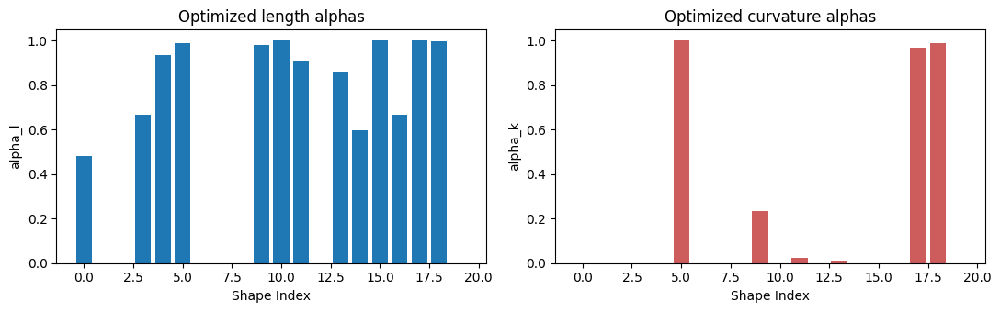

In [26]:
# show alphas
alphas_l = frames[-1].reshape(5, n_shapes)[3]
alphas_k = frames[-1].reshape(5, n_shapes)[4]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
ax1.bar(range(n_shapes), alphas_l)
ax1.set(xlabel="Shape Index", ylabel="alpha_l", title="Optimized length alphas")
ax2.bar(range(n_shapes), alphas_k, color='indianred')
ax2.set(xlabel="Shape Index", ylabel="alpha_k", title="Optimized curvature alphas")
plt.tight_layout(); plt.show()


In [27]:
final_lengs = alphas2lengths(alphas_l)
final_kaps  = alphas2kappas(alphas_k)
print("Final lengths:", final_lengs)
print("Final kappas: ", final_kaps)

# nearest stock point in NORMALIZED (kappa, length) space, so the two axes are comparable
_scale = np.array([max(KAPPA_RANGE[1] - KAPPA_RANGE[0], 1e-12),
                   max(LENGTH_RANGE[1] - LENGTH_RANGE[0], 1e-12)])
_query = np.stack([final_kaps, final_lengs], axis=1)                     # (N, 2)
nearest_idx = np.argmin(np.linalg.norm((_query[:, None, :] - beam_stock_prams[None, :, :]) / _scale,
                                       axis=2), axis=1)                  # (N,)
snapped = beam_stock_prams[nearest_idx]                                  # (N, 2) [kappa, length]

# reassign each arc to the nearest stock point and recompute the density field
nearest_idx_alphas_l = lengths2alphas(snapped[:, 1])
nearest_idx_alphas_k = kappas2alphas(snapped[:, 0])
x_opt_reassigned = frames[-1].copy()
x_opt_reassigned[3*n_shapes:4*n_shapes] = np.clip(nearest_idx_alphas_l, 0, 1)
x_opt_reassigned[4*n_shapes:5*n_shapes] = np.clip(nearest_idx_alphas_k, 0, 1)
density_field_reassigned = density_func(x_opt_reassigned)

final_beam_stock_distribution = np.bincount(nearest_idx, minlength=len(beam_stock_prams))

print("Final distribution:", final_beam_stock_distribution)
print("Target distribution:", beam_stock_numbs.astype(int))
print("Diff:", final_beam_stock_distribution - beam_stock_numbs.astype(int))


Final lengths: [19.26890006  0.          0.         26.66742883 37.43823482 39.63833684
  0.          0.          0.         39.28925006 40.         36.30140298
  0.         34.44775667 23.9165105  40.         26.66392504 40.
 39.95777067  0.        ]
Final kappas:  [0.02       0.02       0.02       0.02       0.02       0.1
 0.02       0.02       0.02       0.03860761 0.02       0.02200354
 0.02       0.02074755 0.02       0.02       0.02       0.09753079
 0.09919574 0.02      ]
Final distribution: [7 0 0 0 0 0 0 0 0 0 2 0 0 0 0 3 0 0 0 0 4 1 0 0 3]
Target distribution: [30 30 30 30 30  4  4  4  4  4  4  4  4  4  4  4  4  4  4  4  4  4  4  4
  4]
Diff: [-23 -30 -30 -30 -30  -4  -4  -4  -4  -4  -2  -4  -4  -4  -4  -1  -4  -4
  -4  -4   0  -3  -4  -4  -1]


Final Loss: 1280.2150295192916


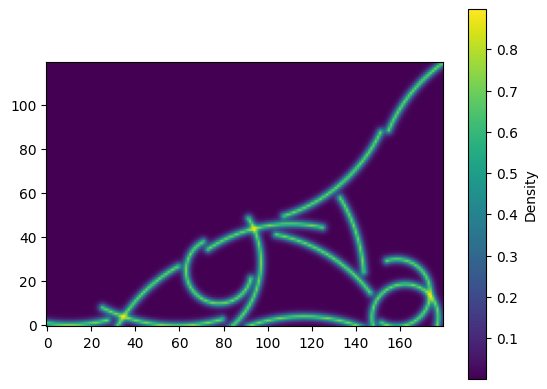

In [28]:
frame = frames[-1].copy()
density_field = params_to_density_map(
    frame, beam_types=beam_types,
    grid_w=grid_w, grid_h=grid_h,
    x_range=x_range, y_range=y_range,
    sdf_x_range=sdf_x_range, sdf_y_range=sdf_y_range, sharpness=sharpness
)

# density_field = density_from_joints
fig, ax = plt.subplots()
plt.colorbar(ax.imshow(density_field, origin='lower'), ax=ax, label='Density')
ax.imshow(density_field, origin='lower')
temp_density_field = density_field
temp_density_field[temp_density_field > 0.4] = 1
print("Final Loss:", env.objective(temp_density_field, volume_constraint=False)  )

joints: (33, 2)
pairs:  (20, 2)
kappa/len: (20, 2)


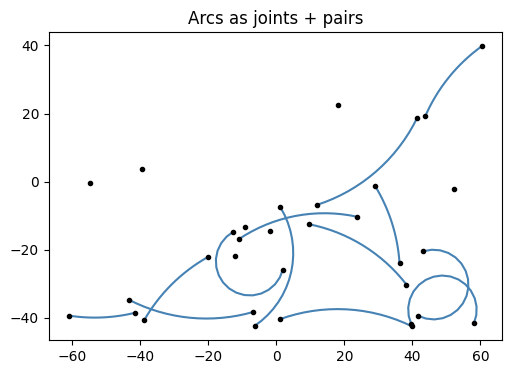

In [29]:
# usage
joint_xy_init, beam_joint_pairs, beam_kappa_len = params_to_joints(frame)
print("joints:", joint_xy_init.shape)        # (M, 2)
print("pairs: ", beam_joint_pairs.shape)     # (N, 2)
print("kappa/len:", beam_kappa_len.shape)    # (N, 2)

# visual check (draw the true arcs, not chords)
plt.figure(figsize=(6, 4))
for i in range(len(beam_joint_pairs)):
    poly = arc_polyline_np(frame, i)
    plt.plot(poly[:, 0], poly[:, 1], '-', color='steelblue')
plt.plot(joint_xy_init[:, 0], joint_xy_init[:, 1], 'ko', markersize=3)
plt.gca().set_aspect('equal')
plt.title('Arcs as joints + pairs')
plt.show()


In [30]:
# usage
save_truss_txt("./results/arc_truss.txt", joint_xy_init, beam_joint_pairs)
print("saved to arc_truss.txt")

# round-trip check
# j2, p2 = load_truss_txt("./results/arc_truss.txt")
# assert np.allclose(j2, joint_xy_init) and np.array_equal(p2, beam_joint_pairs)


saved to arc_truss.txt


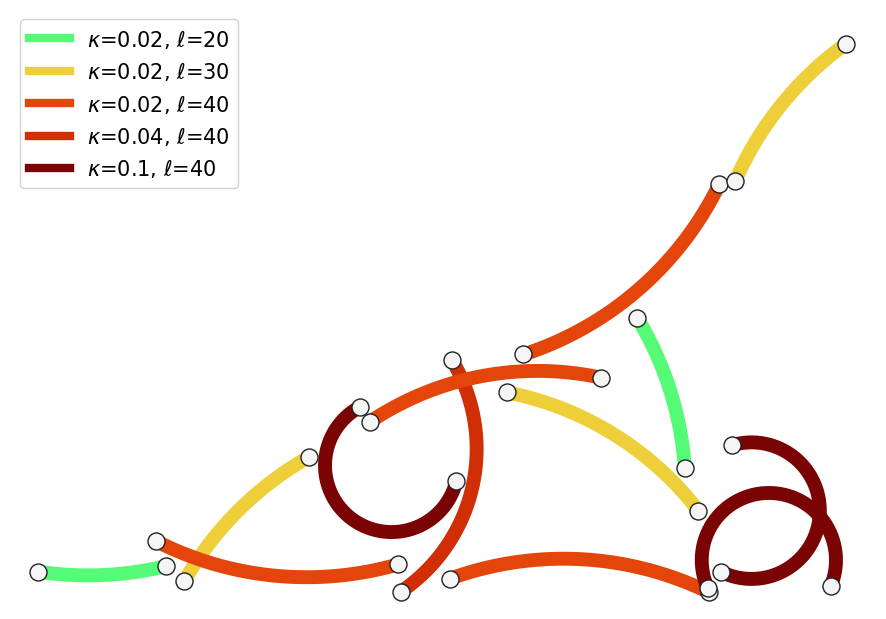

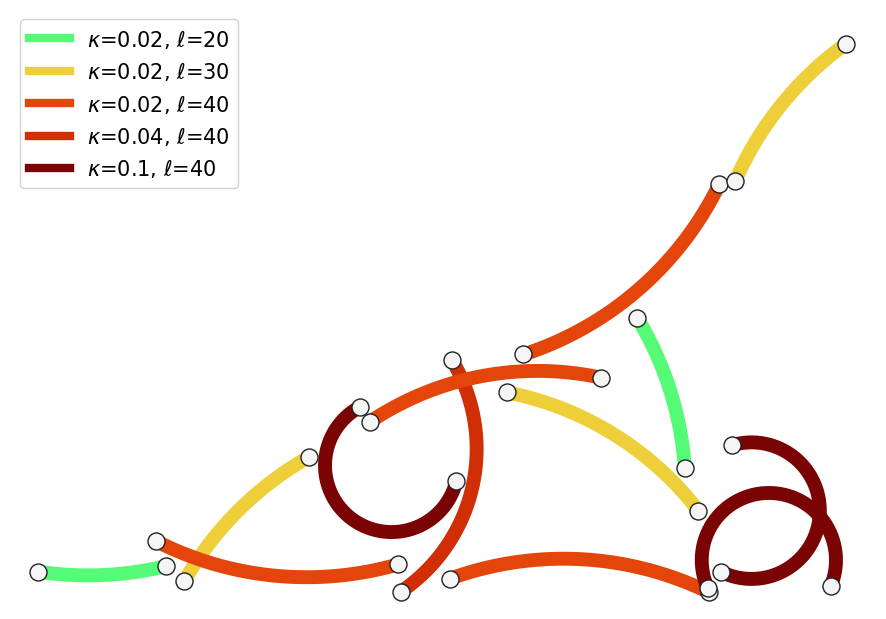

In [39]:
import numpy as np
import matplotlib.pyplot as plt

XLIM = (-65, 65)
YLIM = (-45, 45)
JOINT_TOL = 1e-6
DEAD_LEN = 1e-6

_PALETTE = ["#FF595E", "#FFCA3A", "#8AC926", "#2A7E4D", "#184495",
            "#6A4C93", "#FF924C", "#55A7D9", "#B5179E", "#7F4F24",
            "#00B4D8", "#E76F51", "#9D0208", "#3A0CA3", "#F72585",
            "#606C38", "#FFB703", "#0F4C5C", "#D4A373", "#4CC9F0"]
if len(beam_stock_prams) <= len(_PALETTE):
    STOCK_COLORS = {i: _PALETTE[i] for i in range(len(beam_stock_prams))}
else:   # more stock points than hand-picked colors -> sample a colormap evenly
    cmap = plt.get_cmap('turbo')
    STOCK_COLORS = {i: cmap(i / max(len(beam_stock_prams) - 1, 1))
                    for i in range(len(beam_stock_prams))}


def _arc_polyline(cx, cy, theta, L, kap, n=64):
    """World-frame (n,2) polyline of one arc (same convention as _beam_grids_soft)."""
    k = float(kap) + KAPPA_EPS
    R = 1.0 / k
    ph = min(float(L) * k / 2.0, np.pi * 0.999)
    psi = np.linspace(-ph, ph, n)
    lx = R * (1.0 - np.cos(psi))
    ly = R * np.sin(psi)
    c, s = np.cos(theta), np.sin(theta)
    return np.stack([c * lx - s * ly + cx, s * lx + c * ly + cy], axis=1)


def render_x_opt(x_flat, output=None, show_legend=True, show = False):
    n = len(x_flat) // 5
    x, y, theta, al, ak = np.asarray(x_flat).reshape(5, n)
    lens = np.asarray(alphas2lengths(al))
    kaps = np.asarray(alphas2kappas(ak))

    # nearest stock point per beam (normalized (kappa, length) space) -> its color
    scale = np.array([max(KAPPA_RANGE[1] - KAPPA_RANGE[0], 1e-12),
                      max(LENGTH_RANGE[1] - LENGTH_RANGE[0], 1e-12)])
    q = np.stack([kaps, lens], axis=1)
    stock_idx = np.argmin(np.linalg.norm((q[:, None, :] - beam_stock_prams[None]) / scale,
                                         axis=2), axis=1)

    polys, endpoints, used = [], [], []
    for i in range(n):
        if lens[i] < DEAD_LEN:
            continue                                          # dead beam
        P = _arc_polyline(x[i], y[i], theta[i], lens[i], kaps[i])
        inside = ((P[:, 0] >= XLIM[0]) & (P[:, 0] <= XLIM[1]) &
                  (P[:, 1] >= YLIM[0]) & (P[:, 1] <= YLIM[1]))
        if not inside.any():
            print(f"skip beam {i}: whole arc lies outside the canvas")
            continue                                          # fully outside the canvas
        polys.append(P)
        endpoints.append((P[0], P[-1]))
        used.append(i)

    # merge endpoints into joints (only those inside the canvas get a dot)
    joints = []
    for p in [e for pair in endpoints for e in pair]:
        if not (XLIM[0] <= p[0] <= XLIM[1] and YLIM[0] <= p[1] <= YLIM[1]):
            continue
        for qj in joints:
            if np.hypot(*(p - qj)) < max(JOINT_TOL, 1e-9):
                break
        else:
            joints.append(p)
    joints = np.array(joints) if joints else np.empty((0, 2))

    fig, ax = plt.subplots(figsize=(9, 6))                    # same 180:120 proportions
    for P, i in zip(polys, used):
        ax.plot(P[:, 0], P[:, 1], color=STOCK_COLORS[stock_idx[i]],
                linewidth=10, solid_capstyle="round", zorder=2)
    if len(joints):
        ax.scatter(joints[:, 0], joints[:, 1], s=150, c="#f5f5f5",
                   edgecolors="#222", linewidths=1, zorder=4)

    if show_legend:
        present = sorted(set(stock_idx[used]))
        handles = [plt.Line2D([], [], color=STOCK_COLORS[j], lw=6,
                              label=f"$\\kappa$={beam_stock_prams[j,0]:g}, $\\ell$={beam_stock_prams[j,1]:g}")
                   for j in present]
        ax.legend(handles=handles, loc="upper left", fontsize=15, framealpha=0.9)

    ax.set_xlim(*XLIM)
    ax.set_ylim(*YLIM)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_position([0, 0, 1, 1])
    if output is not None:
        fig.savefig(output, dpi=160)
    # plt.show()
    return fig


render_x_opt(frames[-1])
# render_x_opt(x_opt_reassigned)      # the snapped-to-stock version
# render_x_opt(x_opt, output="truss_arcs.png")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

def animate_arc_frames(x_frames, interval=100, save_path=None, dpi=100):
    imgs = []
    for f in x_frames:
        fig = render_x_opt(f, show=False)
        fig.set_dpi(dpi)
        fig.canvas.draw()
        imgs.append(np.asarray(fig.canvas.buffer_rgba()).copy())
        plt.close(fig)                   

    h, w = imgs[0].shape[:2]
    fig, ax = plt.subplots(figsize=(w / dpi, h / dpi), dpi=dpi)
    ax.axis("off")
    ax.set_position([0, 0, 1, 1])
    im = ax.imshow(imgs[0])

    def update(k):
        im.set_array(imgs[k])
        return [im]

    anim = FuncAnimation(fig, update, frames=len(imgs),
                         interval=interval, blit=True)

    if save_path is not None:
        if save_path.endswith(".gif"):
            anim.save(save_path, writer="pillow", fps=1000 // interval)
        elif save_path.endswith(".mp4"):
            anim.save(save_path, writer="ffmpeg", fps=1000 // interval)
        else:
            raise ValueError("Unsupported format. Use .mp4 or .gif")

    plt.close(fig)
    return HTML(anim.to_jshtml())


import numpy as np
from scipy.ndimage import uniform_filter1d

raw = np.array(all_frames)
smooth = uniform_filter1d(raw, size=5, axis=0, mode='nearest')

animate_arc_frames(smooth[::4], save_path="./arc.gif")